# Step 4 — Temperature-Balanced SSL DataLoaders, Physical Raman Augmentations, Contiguous Block Masking & Zero-Leakage Patient Splits (`src/spectrabreast/data/`)

This notebook documents and validates **Step 4** of the `SPECTRA-BREAST` pipeline, bridging the `1,000`-point tensors in `data/02_ready/` with the Self-Supervised Pre-Training (`1D-ViT SMAE` and `1D-ResNet-34 Barlow Twins`) and Downstream Fine-Tuning models:
1. **Temperature-Balanced Cohort Sampling ($P_\alpha(c) \propto N_c^{0.5}$)**: Prevents massive datasets (`pdo_hw_maps`, `deepr`) from drowning out smaller specialized cohorts (`spectrabreast_fp`, `riverd_meat_hw`, `raman_mae`) without over-repeating small cohorts $160\times$.
2. **Physically Grounded Raman Augmentations (`RamanPhysicalAugmentor`)**: Generates correlated views $(Y_A, Y_B)$ for `1D-ResNet-34 (Barlow Twins)` using sub-pixel grating drift, smooth optical transmission envelopes, residual quadratic fluorescence curvature, and heteroscedastic Poisson-Gaussian CCD shot noise.
3. **Contiguous Multi-Block Spectral Masking (`SpectralBlockMaskGenerator`)**: Masks `75%` (`38/50` patches of `20` points) in contiguous spans of `2–6` patches (`40–120` channels) so `1D-ViT (SMAE)` cannot cheat via local interpolation and must learn long-range vibrational couplings.
4. **Zero-Leakage Patient/Subject-Grouped Cross-Validation Splits (`data/02_ready/downstream/splits/`)**: Enforces `StratifiedGroupKFold(n_splits=5)` grouped by patient (`riverd_oral_hw`, `ibd`) or mouse (`dataset_renzo`), guaranteeing **`0.0%` subject leakage**.

## 1. Environment Setup & Imports
Import standard libraries and the Step 4 components from `spectrabreast.data`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

from spectrabreast.data import (
    RamanPhysicalAugmentor, SpectralBlockMaskGenerator,
    SSLPretrainDataset, DownstreamFoldLoader,
    build_and_verify_downstream_splits, plot_cohort_sampling_balance,
    plot_barlow_twins_physical_augmentations, plot_smae_contiguous_block_masking,
    plot_downstream_grouped_splits_audit,
)

ROOT = Path('..').resolve()
READY_DIR = ROOT / 'data' / '02_ready'
FIG_DIR = ROOT / 'docs' / 'figures' / '04_dataloaders_augmentations'

Ready directory : c:\Users\alexf\Desktop\SPECTRA-BREAST\data\02_ready
Figures output  : c:\Users\alexf\Desktop\SPECTRA-BREAST\docs\figures\04_dataloaders_augmentations


## 2. Figure 1 — Temperature-Balanced SSL Cohort Sampling ($\alpha = 0.5$)
Compare Naive Uniform sampling ($\alpha = 1.0$), Square-Root Temperature Balancing ($\alpha = 0.5$, recommended), and Equal Cohort sampling ($\alpha = 0.0$) across `ViT-FP`, `ViT-HW`, and `CNN-All`.

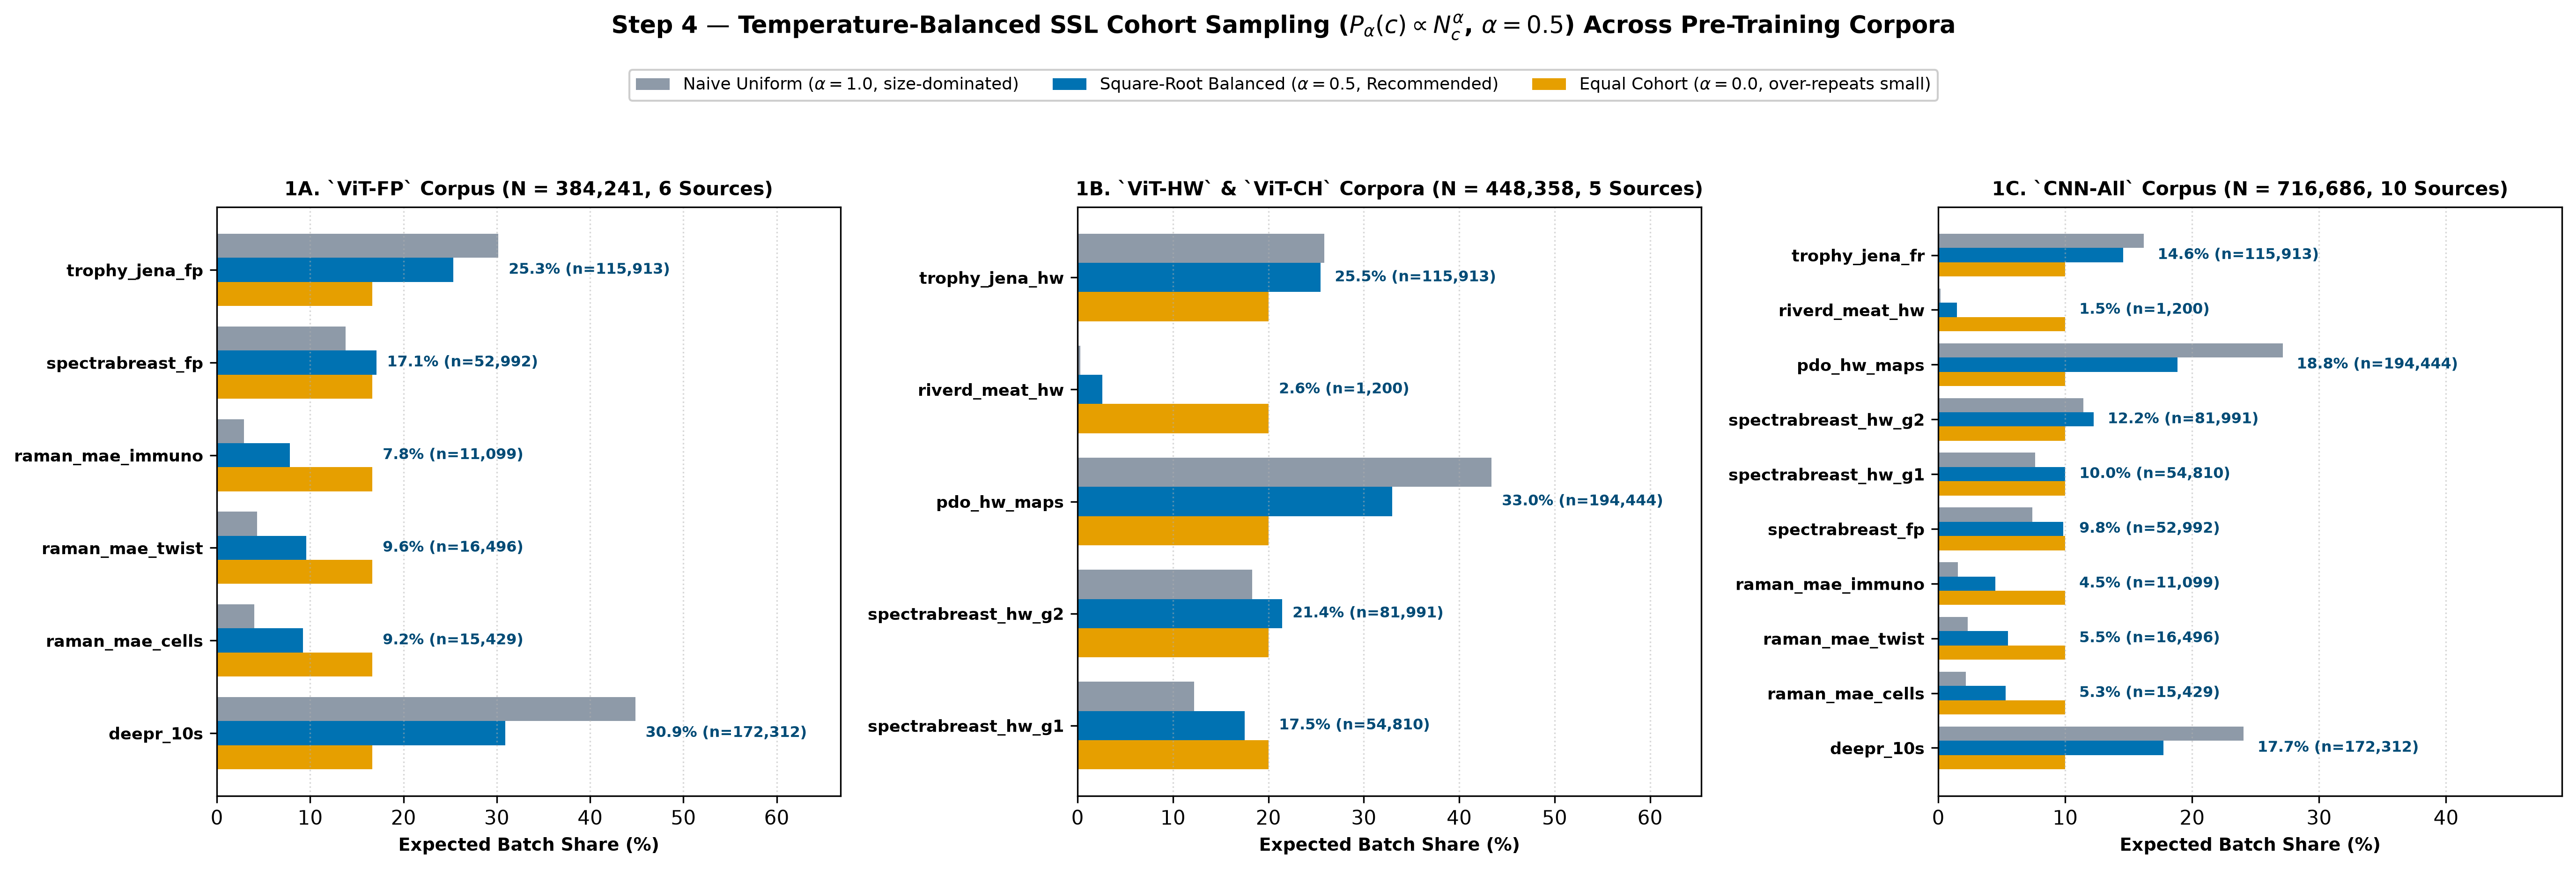

In [2]:
fig1_path = FIG_DIR / 'fig1_cohort_sampling_balance.png'
plot_cohort_sampling_balance(READY_DIR, out_paths=[fig1_path])

## 3. Interactive SSL Mini-Batch Sampling (`SSLPretrainDataset`)
Verify batch shapes, value bounds (`[0.0000, 1.0000]`), and mask ratios in both `mode='smae'` (`1D-ViT`) and `mode='barlow_twins'` (`1D-ResNet-34`).

In [3]:
ds_smae = SSLPretrainDataset(READY_DIR / 'pretrain/FP/pretrain_vit_fp_1000.npz', mode='smae', sampling_alpha=0.5)
b_smae = ds_smae.sample_batch(batch_size=64, balanced=True, seed=42)
print('SMAE Batch     :', b_smae['spectra'].shape, '| Patch mask:', b_smae['patch_mask'].shape, '| Masked ratio:', b_smae['patch_mask'].mean())

ds_bt = SSLPretrainDataset(READY_DIR / 'pretrain/CNN/pretrain_cnn_all_1000.npz', mode='barlow_twins', sampling_alpha=0.5)
b_bt = ds_bt.sample_batch(batch_size=64, balanced=True, seed=42)
print('BarlowTwins Bch:', b_bt['view_1'].shape, b_bt['view_2'].shape, f"| Range: [{b_bt['view_1'].min():.4f}, {b_bt['view_1'].max():.4f}]")

SMAE Batch     : (64, 1000) | Patch mask: (64, 50) | Masked ratio: 0.76
BarlowTwins Bch: (64, 1000) (64, 1000) | Range: [0.0000, 1.0000]


## 4. Figure 2 — Physical Raman Augmentations for `1D-ResNet-34 (Barlow Twins)`
Visualize correlated augmented views $(Y_A, Y_B)$ on `FP` and `HW` spectra, the decomposition of the 4 physical perturbation terms, and comparison against real paired `deepr` (`0.1s` vs `1.0s`) acquisitions.

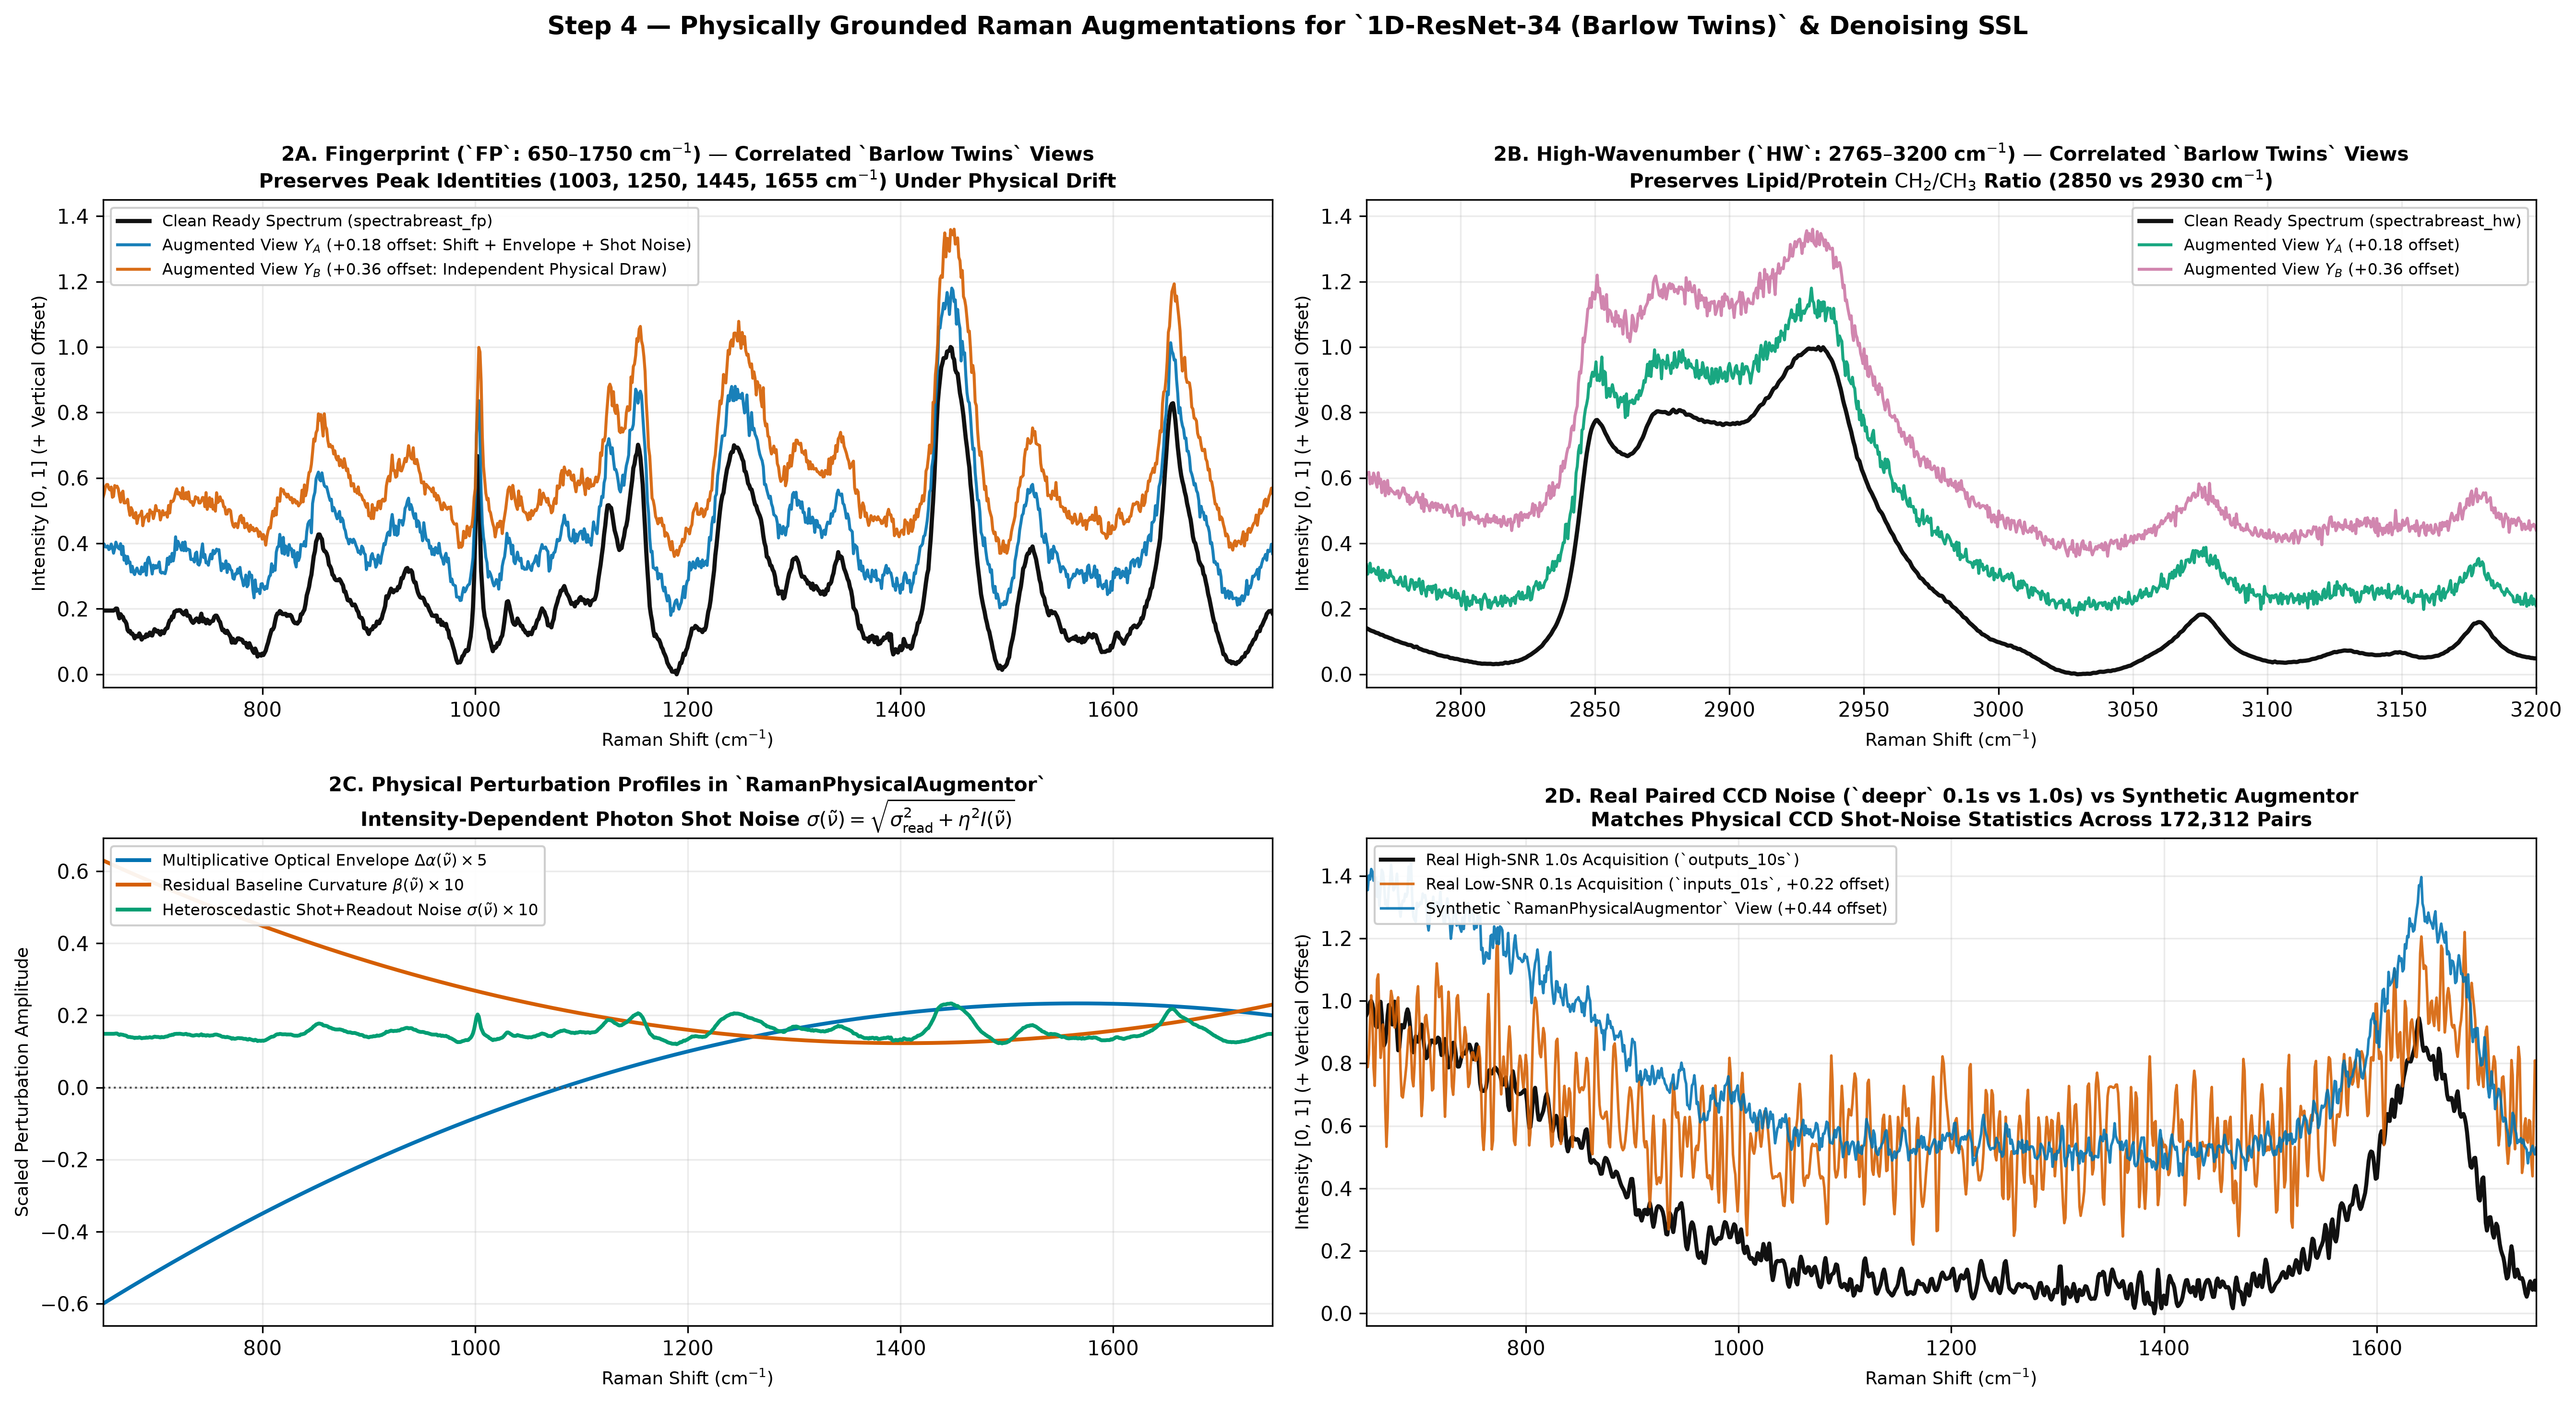

In [4]:
fig2_path = FIG_DIR / 'fig2_barlow_twins_physical_augmentations.png'
plot_barlow_twins_physical_augmentations(READY_DIR, out_paths=[fig2_path])

## 5. Figure 3 — Contiguous Multi-Block Patch Masking for `1D-ViT (SMAE)`
Compare Contiguous Multi-Block Masking (`38/50` patches masked in contiguous blocks of `2–6` patches = `40–120` channels) against standard Random Patch Masking across `ViT-FP` and `ViT-HW`.

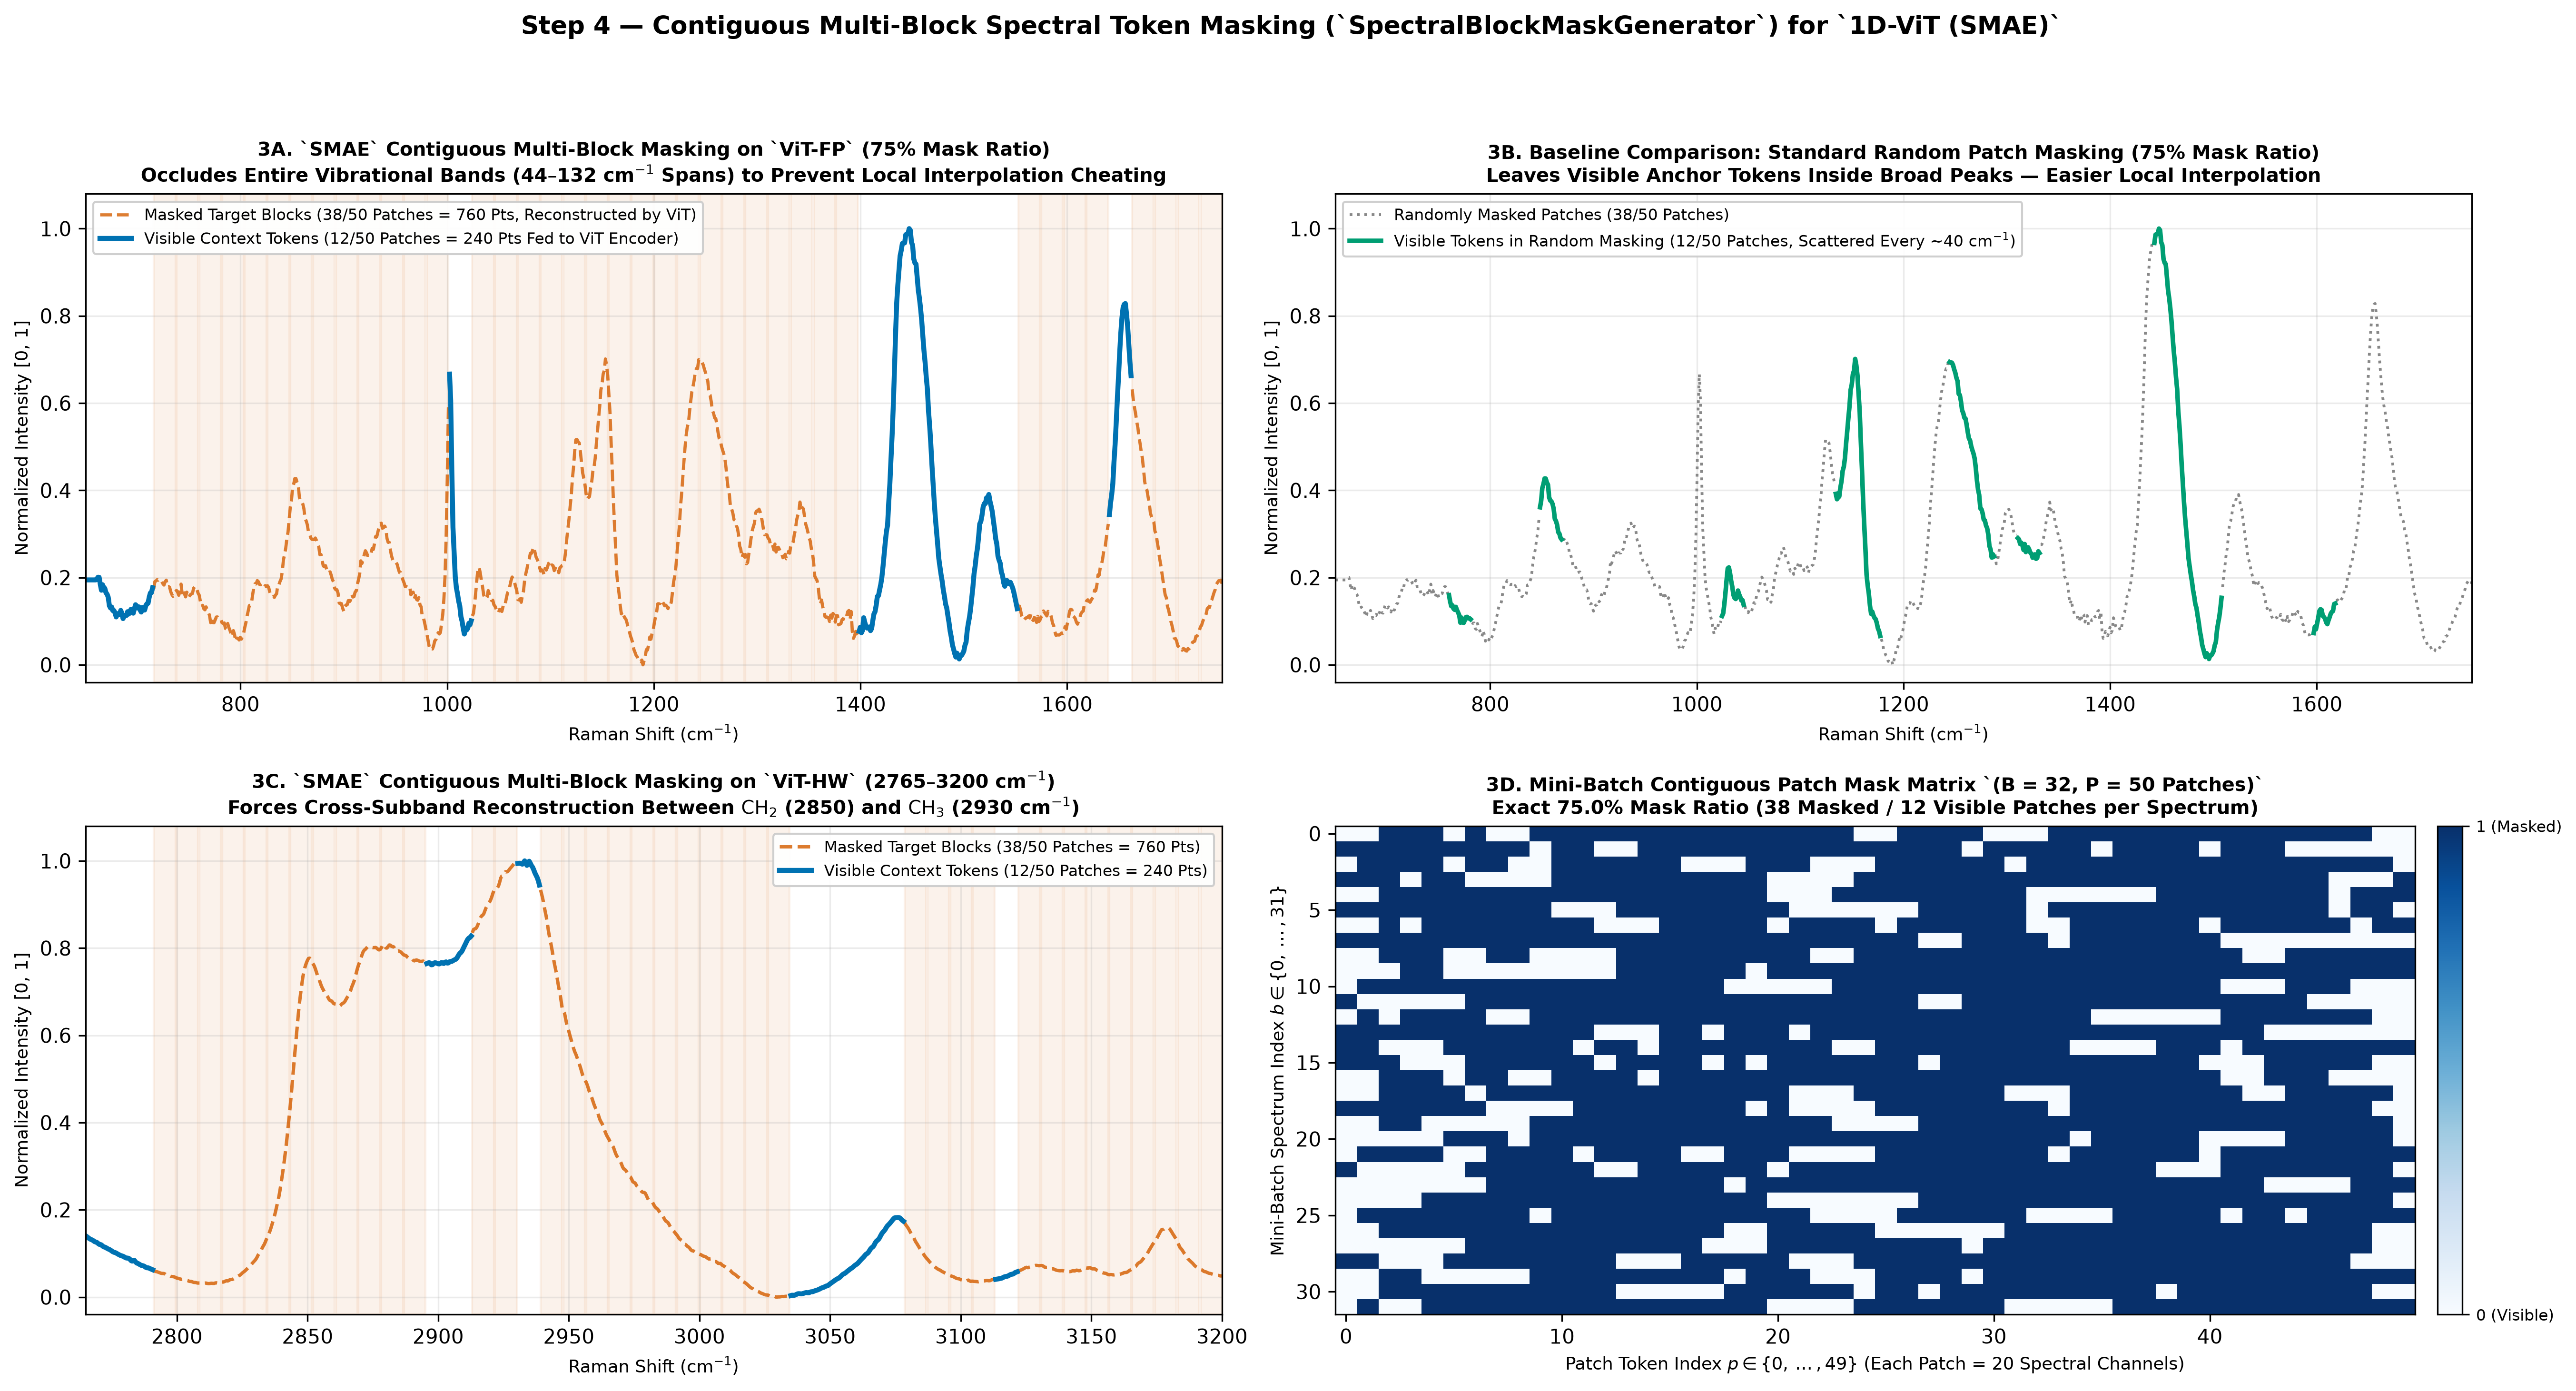

In [5]:
fig3_path = FIG_DIR / 'fig3_smae_contiguous_block_masking.png'
plot_smae_contiguous_block_masking(READY_DIR, out_paths=[fig3_path])

## 6. Leakage-Free Patient/Subject-Grouped Cross-Validation Splits (`docs/downstream_splits_catalog.csv`)
Inspect the 5-fold evaluation splits generated in `data/02_ready/downstream/splits/` and verify that `Subject_Overlap_Leakage == 0` across every fold of every benchmark.

In [6]:
splits_df = pd.read_csv(ROOT / 'docs' / 'downstream_splits_catalog.csv')
print('Total subject leakage across all 16 fold definitions:', splits_df['Subject_Overlap_Leakage'].sum())
display(splits_df)

Total subject leakage across all 16 fold definitions: 0


Benchmark,Regime,Split_Protocol,Fold,Train_Spectra,Test_Spectra,Train_Subjects,Test_Subjects,Subject_Overlap_Leakage,Target_Distribution_Test
ibd (ICSM Plasma),FP (650–1750 cm^-1),5-Fold Stratified Patient CV,Fold 1,183,45,183,42,0,"HC=18, IBD=27"
ibd (ICSM Plasma),FP (650–1750 cm^-1),5-Fold Stratified Patient CV,Fold 2,182,46,179,46,0,"HC=19, IBD=27"
ibd (ICSM Plasma),FP (650–1750 cm^-1),5-Fold Stratified Patient CV,Fold 3,183,45,180,45,0,"HC=18, IBD=27"
ibd (ICSM Plasma),FP (650–1750 cm^-1),5-Fold Stratified Patient CV,Fold 4,182,46,179,46,0,"HC=19, IBD=27"
ibd (ICSM Plasma),FP (650–1750 cm^-1),5-Fold Stratified Patient CV,Fold 5,182,46,179,46,0,"HC=19, IBD=27"
bacteria_id (30 Pathogens),FP (650–1750 cm^-1),Official Finetune (5-Fold Val) + Held-Out Test,Official Split (5-Fold Val),2400,3000,30,30,0,"30 Classes × 100 Clinical Isolates = 3,000 Test (+ 600 Val)"
riverd_oral_hw / ch (OSCC Surgery),HW (2765–3200) & CH (2800–3045),5-Fold StratifiedGroupKFold (by Patient sample_id),Fold 1,6741,1681,147,39,0,"Normal=1182, Tumor=499"
riverd_oral_hw / ch (OSCC Surgery),HW (2765–3200) & CH (2800–3045),5-Fold StratifiedGroupKFold (by Patient sample_id),Fold 2,6741,1681,155,31,0,"Normal=1188, Tumor=493"
riverd_oral_hw / ch (OSCC Surgery),HW (2765–3200) & CH (2800–3045),5-Fold StratifiedGroupKFold (by Patient sample_id),Fold 3,6730,1692,153,33,0,"Normal=1196, Tumor=496"
riverd_oral_hw / ch (OSCC Surgery),HW (2765–3200) & CH (2800–3045),5-Fold StratifiedGroupKFold (by Patient sample_id),Fold 4,6750,1672,143,43,0,"Normal=1158, Tumor=514"


## 7. Verify `DownstreamFoldLoader` on Fold 0 Across All 4 Benchmarks
Load Fold 0 for `ibd`, `bacteria_id`, `riverd_oral_hw`, and `dataset_renzo` and verify zero overlap between `train_groups` and `test_groups`.

In [7]:
loader = DownstreamFoldLoader(READY_DIR)
for bm in ['ibd', 'bacteria_id', 'riverd_oral_hw', 'dataset_renzo']:
    f0 = loader.get_fold(bm, fold=0)
    ov = len(set(f0.get('train_groups', [])).intersection(set(f0.get('test_groups', []))))
    print(f"{bm:16s} | Train: {str(f0['X_train'].shape):12s} | Test: {str(f0['X_test'].shape):12s} | Group Overlap: {ov}")

ibd              | Train: (182, 1000)  | Test: (46, 1000)   | Group Overlap: 0
bacteria_id      | Train: (2400, 1000) | Test: (3000, 1000) | Group Overlap: 0
riverd_oral_hw   | Train: (6742, 1000) | Test: (1680, 1000) | Group Overlap: 0
dataset_renzo    | Train: (2560, 1000) | Test: (640, 1000)  | Group Overlap: 0


## 8. Figure 4 — Zero-Leakage Patient/Subject-Grouped Splits Audit (`data/02_ready/downstream/splits/`)
Render the 2x2 fold stratification audit across `ibd`, `riverd_oral_hw`, `dataset_renzo`, and `bacteria_id`.

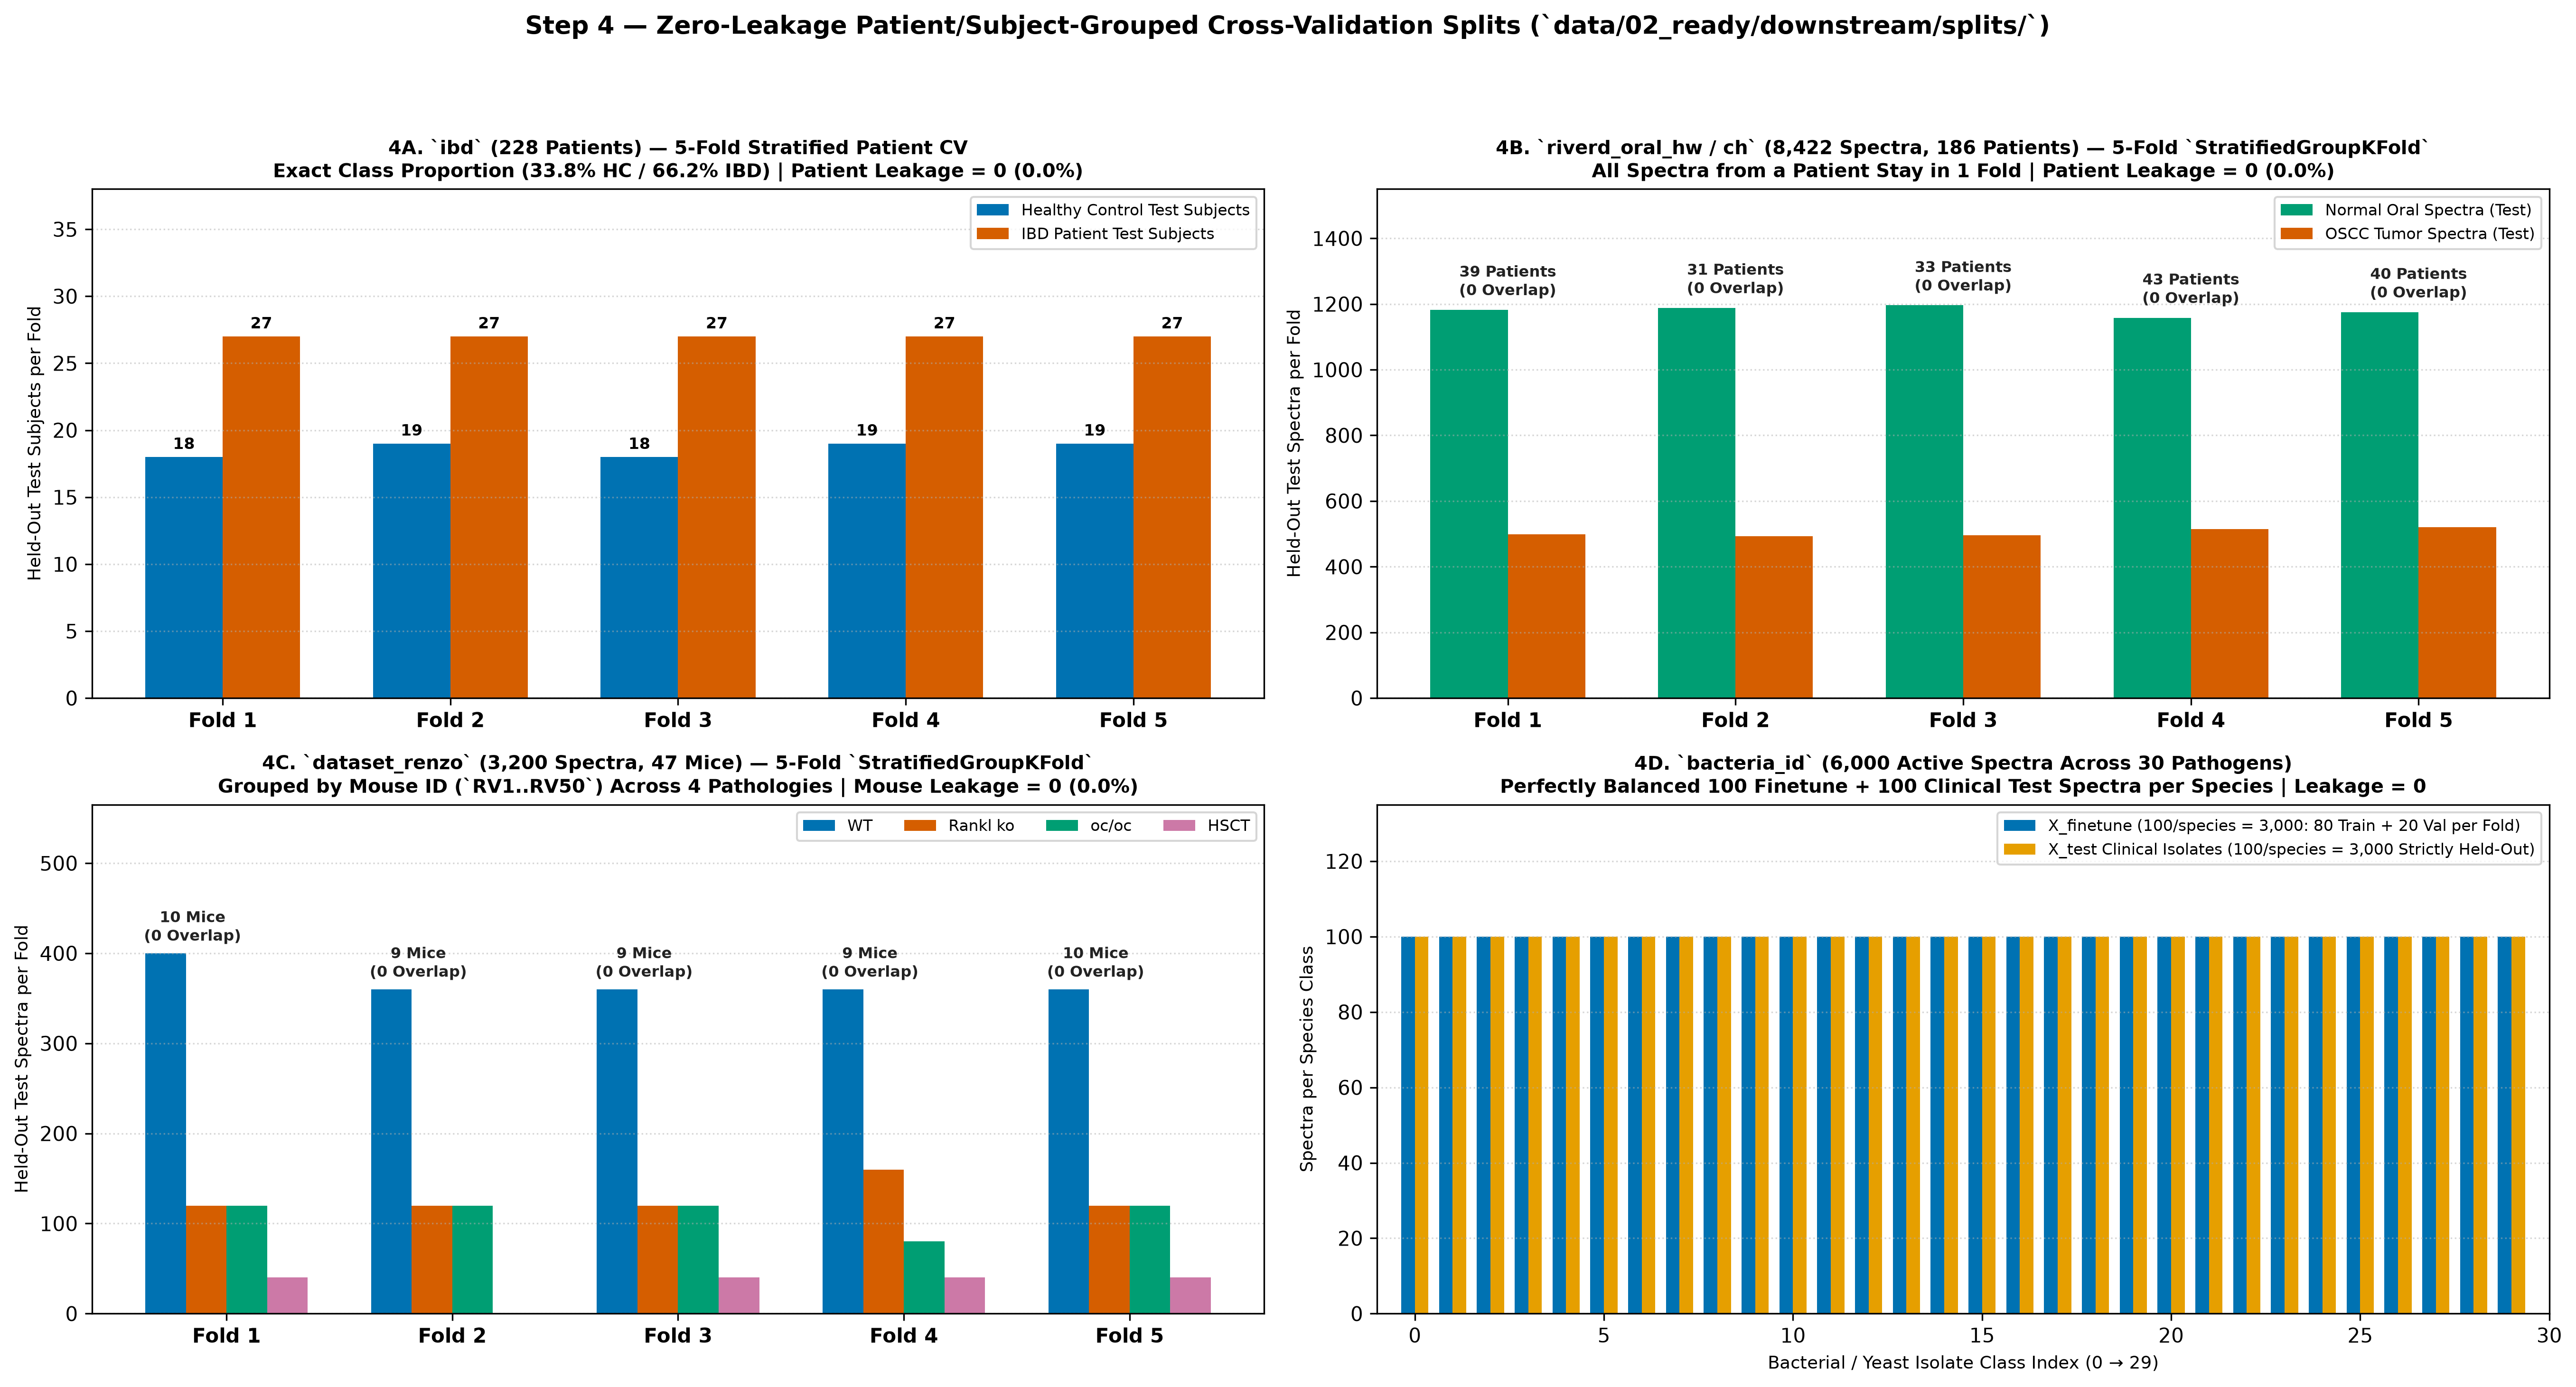

In [8]:
fig4_path = FIG_DIR / 'fig4_downstream_grouped_splits_audit.png'
_, split_details = build_and_verify_downstream_splits(READY_DIR)
plot_downstream_grouped_splits_audit(split_details, out_paths=[fig4_path])